<a href="https://colab.research.google.com/github/bsyeol/26AI_project/blob/main/SynSEPA/FDS_SynSEPA_Full_Restricted_4Encoders_TabPFN35.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SynSEPA | Full vs Restricted | 4 sequence encoders + TabPFN 3.5
기존 FDS 모델의 계좌 중심 시계열 성능 재현 실험. **Seed 0, 20 encoder fits, 44 classifier runs.**

- Full: amount_log, time_band, weekday, persona, remittance_category, beneficiary_country, country_type (7). Restricted: 국가 두 변수만 제외 (5). 두 조건 모두 `is_new_beneficiary`, `time_since_last_txn`, `remittance_text`, `fraud_type`, 계좌 ID는 모델 입력에서 제외. Full은 모든 원본 컬럼이라는 뜻이 아니라 사전 합의한 7개 특징 조건이다.
- History (7): 3시간 단위 count, total, mean, max, distinct beneficiary, distinct remittance category, observed. 현재 bin 전체 제외. 과거 라벨 미사용. Test 기간에도 이미 관측된 과거 거래 특징만 순차적으로 조회한다. 전체 거래의 비라벨 이력은 이용 가능하다고 가정한다.
- 날짜순 70/15/15 Train/Val/Test. Train의 원본 비율로 9,996개 라벨을 추출해 fit/tune 80/20. Val 전체로 threshold 선정, Test 전체 평가. Seed/row/encoder는 두 조건에서 공유한다. 범주 코드 사전은 Train 거래의 비라벨 특징만으로 구성한다.
- 기존 하이퍼파라미터 유지: GRU 32, Matched TF 20/FF32, SIGMA 64/state32/expand2/conv4/recent5, Time2Vec TF 32/FF64/time8. 32차원 embedding, AdamW 0.001, 최대 20 epochs, patience 3, batch 256. TabPFN 3.5 pretrained, no fine-tuning.
- 1/2/7/14/30일. Full/Restricted별 LightGBM·TabPFN 현재거래 baseline 2개씩. 시계열 모델의 학습은 조건별 반복하지 않는다.
- 결과는 `processed/synsepa/four_encoders_full_restricted_v1/`에 저장. 기존 Handbook/원본 실험에 영향 없음. 연결 종료 후 공통 셀 재실행 → 원하는 Part 실행. 완료 classifier는 건너뛰며 완료 encoder checkpoint 재사용. 중단된 encoder 자체의 epoch 중간 재개는 지원하지 않는다.
- 국가 특징의 shortcut은 Train 분석에서 발견했다. Full과 Restricted를 모두 보고하고 Test 결과를 보고 실험 조건을 변경하지 않는다. Restricted에도 합성 데이터 편향이 남을 수 있다. 단일 seed는 탐색적 비교이며 Time2Vec의 독립 효과는 이 실험만으로 입증할 수 없다 (backbone 폭 차이).

In [32]:
# 1. Colab 설치: 기존 실험 버전 유지
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError
packages={'tabpfn':'10.2.0','lightgbm':'4.7.0','pyarrow':'26.0.1'}
need=[]
for p,v in packages.items():
    try: installed=version(p)
    except PackageNotFoundError: installed=None
    if installed!=v: need.append(f'{p}=={v}')
if need: subprocess.check_call([sys.executable,'-m','pip','install','-q',*need])
# 이미 import된 패키지가 변경됐다면 런타임 재시작
# SynSEPA download support
subprocess.check_call([sys.executable,"-m","pip","install","-q","datasets"])

0

## Part 0. SynSEPA 다운로드 및 전처리 (최초 1회)
기존 처리 파일이 있으면 무결성 확인 후 재사용합니다. 이 셀은 GPU 학습을 하지 않습니다.

In [33]:
from google.colab import drive
from pathlib import Path
import os, json, hashlib, gc
import numpy as np
import pandas as pd
from datasets import load_dataset
from huggingface_hub import HfApi

drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/26-2_AI_project/processed/synsepa')
ROOT.mkdir(parents=True,exist_ok=True)
RESTRICTED=['amount_log','time_band','weekday','persona','remittance_category']
FULL=RESTRICTED+['beneficiary_country','country_type']
AGG=['count','total','mean','max','beneficiary_count','purpose_count']

def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''): h.update(b)
    return h.hexdigest()

def preprocess(raw):
    cols=['transaction_id','account_id','timestamp','amount','persona','remittance_category','beneficiary_iban','beneficiary_country','country_type','is_fraud','fraud_type']
    assert set(cols)<=set(raw.columns), f'Missing: {set(cols)-set(raw.columns)}'
    data=raw[cols].copy().rename(columns={'account_id':'customer_id','beneficiary_iban':'terminal_id','is_fraud':'label','fraud_type':'fraud_scenario'})
    data['timestamp']=pd.to_datetime(data.timestamp,errors='raise')
    data=data.sort_values(['timestamp','transaction_id']).reset_index(drop=True)
    assert not data.isna().any().any() and data.transaction_id.is_unique
    assert np.isfinite(data.amount).all() and (data.amount>=0).all() and set(data.label.unique())=={0,1}
    data['label']=data.label.astype('int8')
    data['amount_log']=np.log1p(data.amount)
    data['time_band']=(data.timestamp.dt.hour//3).astype('int32')
    data['weekday']=data.timestamp.dt.dayofweek.astype('int32')
    data['date']=data.timestamp.dt.normalize()
    data['bin_id']=((data.timestamp-data.date.min())//pd.Timedelta(hours=3)).astype('int64')
    dates=np.sort(data.date.unique()); assert len(dates)>=60
    train_end=dates[int(len(dates)*.70)]; val_end=dates[int(len(dates)*.85)]
    data['split']=np.select([data.date<train_end,data.date<val_end],['train','val'],default='test')
    # Aggregate original purpose strings BEFORE coding; preserves diversity for unseen categories.
    history=data.groupby(['customer_id','bin_id'],sort=True).agg(
        count=('amount','size'),total=('amount','sum'),mean=('amount','mean'),max=('amount','max'),
        beneficiary_count=('terminal_id','nunique'),purpose_count=('remittance_category','nunique')).reset_index()
    history[AGG]=np.log1p(history[AGG]).astype('float32')
    data['purpose_raw']=data.remittance_category  # independent history verification, never model input
    maps={}
    for col in FULL[3:]:
        cats=sorted(data.loc[data.split=='train',col].astype(str).unique().tolist())
        mapping={v:i+1 for i,v in enumerate(cats)}  # 0: unseen category, no future vocab fitting
        maps[col]=mapping
        data[col]=data[col].astype(str).map(mapping).fillna(0).astype('int32')
    return data,history,maps

settings_path=ROOT/'settings.json'
if settings_path.exists():
    S0=json.loads(settings_path.read_text())
    assert S0['DESIGN']=='synsepa_full_restricted_v1', 'Different preprocessing version; use a new folder'
    for name,digest in S0['FILES'].items():
        assert (ROOT/name).exists() and file_sha(ROOT/name)==digest, f'Incomplete or changed file: {name}'
    print('Reused:',ROOT)
else:
    # Freeze the dataset revision on the first run, then reuse saved data.
    repo='EpiphanyTech/SynSEPA'; revision=HfApi().dataset_info(repo).sha
    raw=load_dataset(repo,'transactions',split='train',revision=revision).to_pandas()
    assert (len(raw),int(raw.is_fraud.sum()))==(1839560,7112), 'Dataset version changed; verify before experimenting'
    data,history,maps=preprocess(raw); del raw; gc.collect()
    for name,table in [('full_v1.parquet',data),('history_3h.parquet',history)]:
        tmp=ROOT/(name+'.tmp'); table.to_parquet(tmp,index=False); os.replace(tmp,ROOT/name)
    S0=dict(DESIGN='synsepa_full_restricted_v1',DATASET=repo,REVISION=revision,
            BASE_FEATURES=FULL,RESTRICTED_FEATURES=RESTRICTED,CATEGORICAL_FEATURES=FULL[1:],
            HISTORY_FEATURES=AGG+['observed'],BIN_HOURS=3,HISTORY_LOG_TRANSFORMED=True,
            LABEL='label',USER='customer_id',TERMINAL='terminal_id',HIDDEN=32,TIME_DIM=8,
            CATEGORY_MAPS=maps,WINDOW_DAYS=[1,2,7,14,30],LABEL_BUDGET=9996,
            FILES={n:file_sha(ROOT/n) for n in ['full_v1.parquet','history_3h.parquet']})
    tmp=settings_path.with_suffix('.tmp'); tmp.write_text(json.dumps(S0,indent=2,ensure_ascii=False)); os.replace(tmp,settings_path)
    del data,history; gc.collect()
audit=pd.read_parquet(ROOT/'full_v1.parquet',columns=['split','label','date'])
display(audit.groupby('split').agg(transactions=('label','size'),fraud=('label','sum'),rate=('label','mean'),start=('date','min'),end=('date','max')).reindex(['train','val','test']))
print('Saved dataset:',ROOT,'revision:',S0['REVISION']); del audit

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Reused: /content/drive/MyDrive/26-2_AI_project/processed/synsepa


,transactions,fraud,rate,start,end
split,,,,,
train,1288140,3592,0.002789,2024-01-01,2024-09-12
val,273695,608,0.002221,2024-09-13,2024-11-06
test,277725,2912,0.010485,2024-11-07,2024-12-31


Saved dataset: /content/drive/MyDrive/26-2_AI_project/processed/synsepa revision: bf1496693743159874b53e051c657b3e5dd20393


## 공통 실험 설정 및 데이터 로드
아래 공통 셀을 모두 실행한 뒤 Part 1~5를 선택 실행하세요. A100 권장. Colab Secrets에 기존 `TABPFN_TOKEN`을 등록합니다.

In [34]:
# 2. 설정 / 경로 / 재현성
from google.colab import drive, userdata
import os, json, gc, time, hashlib, random, uuid, math, ast, re, urllib.request
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
from torch import nn
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, precision_recall_curve, auc, roc_curve
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/26-2_AI_project/processed/synsepa')
OUT=ROOT/'four_encoders_full_restricted_v1'
for d in [OUT,OUT/'runs',OUT/'checkpoints',OUT/'provenance',OUT/'plots',OUT/'sessions']:
    d.mkdir(parents=True,exist_ok=True)
S=json.loads((ROOT/'settings.json').read_text())
BASE=S['BASE_FEATURES']; CAT=S['CATEGORICAL_FEATURES']; HIST=S['HISTORY_FEATURES']
BASES={'Full':BASE,'Restricted':S['RESTRICTED_FEATURES']}
CATS={k:[c for c in CAT if c in cols] for k,cols in BASES.items()}
CAT_IDXS={k:[cols.index(c) for c in CATS[k]] for k,cols in BASES.items()}
assert BASE==['amount_log','time_band','weekday','persona','remittance_category','beneficiary_country','country_type']
assert BASES['Restricted']==BASE[:5] and CAT==BASE[1:]
assert HIST==['count','total','mean','max','beneficiary_count','purpose_count','observed'] and S['BIN_HOURS']==3
assert S['LABEL']=='label' and S['USER']=='customer_id' and S['TERMINAL']=='terminal_id'
assert S['HISTORY_LOG_TRANSFORMED'] is True and S['DESIGN']=='synsepa_full_restricted_v1'
DH=len(HIST); AGG=HIST[:-1]; HIDDEN=32; TIME_DIM=8
RUN_DAYS=[1,2,7,14,30]; RUN_SEEDS=[0]  # 변경 시 새 실험 폴더 사용; 모든 모델 동일 seed
LABEL_BUDGET=9996; GRU_EPOCHS=20; GRU_PATIENCE=3; GRU_LR=1e-3; GRU_BATCH=256
TF_DIM=20; TF_HEADS=4; TF_LAYERS=1; TF_FF=32; TF_DROPOUT=.1
SIGMA_DIM=64; SIGMA_STATE=32; SIGMA_CONV=4; SIGMA_EXPAND=2; SIGMA_LAYERS=1; SIGMA_DROPOUT=.2; KEEP_RECENT=5
SIGMA_MICRO_BATCH=32; SIGMA_INFER_BATCH=128
SIGMA_COMMIT='a3f63751503eca869338fc9c8b24a05fa128c6ef'
FINAL_EST=4; PRED_BATCH=4096; MAX_TREES=2000; LGB_PATIENCE=50; TARGET_FPR=.001; REVIEW_TARGET_RECALL=.30
THREADS=min(8,os.cpu_count() or 1); DEVICE='cuda'; SESSION=uuid.uuid4().hex[:12]
assert torch.cuda.is_available(), 'GPU 런타임으로 변경하세요'
assert hasattr(ModelVersion,'V3_5'), 'TabPFN 3.5 API 필요'
if not os.environ.get('TABPFN_TOKEN'):
    for k in ('TABPFN_TOKEN','TABPFN_API_KEY'):
        try: token=userdata.get(k)
        except Exception: continue
        if token: os.environ['TABPFN_TOKEN']=token; del token; break
assert os.environ.get('TABPFN_TOKEN'), 'Colab Secrets의 TABPFN_TOKEN 확인'
ENV=dict(gpu=torch.cuda.get_device_name(0),cuda=torch.version.cuda,versions={p:version(p) for p in ['tabpfn','torch','lightgbm','pyarrow','numpy','pandas','scikit-learn']})
NAMES={'gru':'GRU','matched':'Matched Transformer','sigma':'SIGMA','time2vec':'Transformer + Time2Vec'}
def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''): h.update(b)
    return h.hexdigest()
def write_json(p,obj):
    tmp=p.with_suffix(p.suffix+'.tmp'); tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False)); os.replace(tmp,p)
def write_npz(path,**kw):
    path=Path(path); tmp=path.with_suffix(path.suffix+'.tmp')
    with open(tmp,'wb') as f: np.savez_compressed(f,**kw)
    os.replace(tmp,path)
def write_csv(p,df):
    tmp=p.with_suffix(p.suffix+'.tmp'); df.to_csv(tmp,index=False); os.replace(tmp,p)
CONFIG=dict(design='synsepa_full_restricted_4enc_v1',files={n:sha(ROOT/n) for n in ['full_v1.parquet','history_3h.parquet','settings.json']},base=BASES,cat=CATS,history=HIST,days=RUN_DAYS,seeds=RUN_SEEDS,budget=LABEL_BUDGET,split='train_fit_tune_80_20_val_cal_test_full',history_policy='rolling_past_bins_only_no_labels',hidden=HIDDEN,time_dim=TIME_DIM,gru_epochs=GRU_EPOCHS,patience=GRU_PATIENCE,lr=GRU_LR,batch=GRU_BATCH,tf_matched=[TF_DIM,TF_FF,TF_HEADS,TF_LAYERS,TF_DROPOUT],tf_time=[32,64,4,1,.1],sigma=[SIGMA_DIM,SIGMA_STATE,SIGMA_CONV,SIGMA_EXPAND,SIGMA_LAYERS,SIGMA_DROPOUT,KEEP_RECENT,SIGMA_MICRO_BATCH,SIGMA_INFER_BATCH,SIGMA_COMMIT],n_estimators=FINAL_EST,pred_batch=PRED_BATCH,max_trees=MAX_TREES,lgb_patience=LGB_PATIENCE,target_fpr=TARGET_FPR,review_recall=REVIEW_TARGET_RECALL,software=ENV['versions'])
cp=OUT/'config.json'
if cp.exists(): assert json.loads(cp.read_text())==CONFIG, '설정/데이터/라이브러리 변경: 새 OUT 사용'
else: write_json(cp,CONFIG)
write_json(OUT/'sessions'/f'{SESSION}.json',ENV)
print(ENV); print('Output:',OUT)
# Regression check: prediction keyword p must not collide with the path argument.
_tmp=OUT/'write_npz_smoke.npz'; write_npz(_tmp,p=np.array([.2]),cal_p=np.array([.1]))
with np.load(_tmp) as test_file: np.testing.assert_array_equal(test_file['p'],[.2])
_tmp.unlink()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'gpu': 'NVIDIA L4', 'cuda': '13.0', 'versions': {'tabpfn': '10.2.0', 'torch': '2.14.1+cu130', 'lightgbm': '4.7.0', 'pyarrow': '26.0.1', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}}
Output: /content/drive/MyDrive/26-2_AI_project/processed/synsepa/four_encoders_full_restricted_v1


In [35]:
# 3. 공통 행 분할: 원본 비율을 보존한 9,996개 라벨 예산
cols=list(dict.fromkeys(BASE+['label','customer_id','terminal_id','bin_id','date','split','amount','transaction_id','fraud_scenario','purpose_raw']))
df=pd.read_parquet(ROOT/'full_v1.parquet',columns=cols)
assert df.index.equals(pd.RangeIndex(len(df))) and not df.isna().any().any()
assert df.transaction_id.is_unique and set(df.label.unique())=={0,1}
assert set(df.split.unique())=={'train','val','test'}
y=df.label.to_numpy(np.int8); split=df.split.to_numpy(); bins=df.bin_id.to_numpy(np.int64)
train=np.flatnonzero(split=='train'); cal=np.flatnonzero(split=='val'); ev=np.flatnonzero(split=='test')
assert bins[train].max()<bins[cal].min() and bins[cal].max()<bins[ev].min()
assert all(set(y[a])=={0,1} for a in [train,cal,ev])
weights=np.ones(len(ev)); cal_weights=np.ones(len(cal))
P={}; rate=float(y[train].mean()); npos=round(LABEL_BUDGET*rate)
assert 5<=npos<LABEL_BUDGET and (y[train]==1).sum()>=npos and (y[train]==0).sum()>=LABEL_BUDGET-npos
for seed in RUN_SEEDS:
    rng=np.random.default_rng(seed)
    rows=np.sort(np.r_[rng.choice(train[y[train]==1],npos,replace=False),rng.choice(train[y[train]==0],LABEL_BUDGET-npos,replace=False)])
    fit,tune=train_test_split(rows,test_size=.2,random_state=seed,stratify=y[rows])
    fit,tune=np.sort(fit),np.sort(tune)
    assert not np.intersect1d(fit,tune).size and set(y[fit])==set(y[tune])=={0,1}
    P[seed]=dict(enc=fit,clf=fit,tune=tune)
    print(f'Seed {seed}: fit {len(fit):,} (fraud {y[fit].sum()}), tune {len(tune):,} (fraud {y[tune].sum()})')
row_data=dict(cal=cal,eval=ev,**{f'{k}_{s}':v for s,d in P.items() for k,v in d.items()})
rp=OUT/'rows.npz'
if rp.exists():
    with np.load(rp) as old:
        assert set(old.files)==set(row_data) and all(np.array_equal(old[k],v) for k,v in row_data.items())
else: write_npz(rp,**row_data)
print(f'Train rate={rate:.6%}; sample positives={npos}; calibration={len(cal):,}; Test={len(ev):,}')
display(df.groupby('split').label.agg(['size','sum','mean']).reindex(['train','val','test']))

Seed 0: fit 7,996 (fraud 22), tune 2,000 (fraud 6)
Train rate=0.278852%; sample positives=28; calibration=273,695; Test=277,725


,size,sum,mean
split,,,
train,1288140,3592,0.002789
val,273695,608,0.002221
test,277725,2912,0.010485


In [36]:
# 4. Sparse history index / no current bin / no future bin
# Use saved log-transformed aggregates (no second log). Validate independently against raw features.
assert (bins>=0).all() and np.all(bins[1:]>=bins[:-1])
t=bins.copy(); B=int(t.max())+1
u,customers=pd.factorize(df.customer_id,sort=False); u=u.astype(np.int64)
assert (u>=0).all() and int(u.max())*B+B<np.iinfo(np.int64).max
key=u*B+t
hist=pd.read_parquet(ROOT/'history_3h.parquet',columns=['customer_id','bin_id']+AGG)
hu=customers.get_indexer(hist.customer_id); ht=hist.bin_id.to_numpy(np.int64)
assert (hu>=0).all() and (ht>=0).all() and (ht<B).all()
hk=hu.astype(np.int64)*B+ht; order=np.argsort(hk); K=hk[order]; V=hist[AGG].to_numpy(np.float32)[order]
assert len(K)>0 and np.all(K[1:]>K[:-1]) and np.isfinite(V).all() and (V>=0).all()
# All observed bins must agree with the original transactions, including grouping/count.
raw=df.assign(_key=key).groupby('_key',sort=True).agg(count=('amount','size'),total=('amount','sum'),mean=('amount','mean'),max=('amount','max'),beneficiary_count=('terminal_id','nunique'),purpose_count=('purpose_raw','nunique'))
assert np.array_equal(raw.index.to_numpy(),K)
np.testing.assert_allclose(V,np.log1p(raw[AGG].to_numpy(np.float64)),rtol=2e-6,atol=2e-6)
static=df[BASE].copy()
for c in CAT: static[c]=static[c].astype('int32')
assert np.isfinite(static.to_numpy(np.float64)).all()
scenario=df.fraud_scenario.to_numpy(); transaction_ids=df.transaction_id.to_numpy()
del raw,hist,hk,order,hu,ht,df; gc.collect()

def gather(rows,days):
    rows=np.asarray(rows,dtype=np.int64); L=8*days
    assert L>0
    tt=t[rows,None]-np.arange(L,0,-1,dtype=np.int64)[None,:]
    observed=tt>=0
    keys=u[rows,None]*B+np.maximum(tt,0)
    ix=np.searchsorted(K,keys); safe=np.minimum(ix,len(K)-1)
    hit=observed & (ix<len(K)) & (K[safe]==keys)
    z=np.zeros((len(rows),L,DH),np.float32)
    z[hit,:DH-1]=V[safe[hit]]; z[:,:,DH-1]=observed
    return z
r=P[RUN_SEEDS[0]]['enc'][:4]
assert gather(r,1).shape==(len(r),8,DH)
assert np.array_equal(gather(r,30)[:,-8:],gather(r,1))
# Direct audit a few sampled rows: one customer, strictly previous bins only.
for row in np.r_[r,cal[:2],ev[:2]]:
    z=gather([row],2)[0]
    for j,b in enumerate(range(t[row]-16,t[row])):
        if b<0: assert not z[j].any(); continue
        i=np.searchsorted(K,u[row]*B+b)
        expected=V[i] if i<len(K) and K[i]==u[row]*B+b else np.zeros(DH-1)
        np.testing.assert_array_equal(z[j,:-1],expected); assert z[j,-1]==1
print('History index verified:',len(K),'customer × bin groups')

History index verified: 1693892 customer × bin groups


In [37]:
def elapsed_features(z):
    assert z.ndim==3 and z.shape[-1]==DH
    obs=z[:,:,DH-1]>0
    active=obs & (z[:,:,0]>0)
    idx=np.arange(z.shape[1],dtype=np.int32)[None,:]
    last=np.maximum.accumulate(np.where(active,idx,-1),axis=1)
    known=obs & (last>=0)
    hours=np.where(known,3*(idx-last),0).astype(np.float32)
    # fixed transform common to both time arms; no fitted evaluation statistics.
    dt=(np.log1p(hours)/np.log1p(720.)).astype(np.float32)
    return np.stack([dt,known.astype(np.float32)],axis=-1)
# Synthetic test: padding and pre-first-trade unknown, then 0,3,6,0,3 hours.
def test_elapsed():
    z=np.zeros((1,8,DH),np.float32); z[0,1:,DH-1]=1; z[0,[3,6],0]=1
    e=elapsed_features(z)[0]
    np.testing.assert_array_equal(e[:,1],[0,0,0,1,1,1,1,1])
    np.testing.assert_allclose(np.expm1(e[:,0]*np.log1p(720.)),[0,0,0,0,3,6,0,3],atol=1e-5)
    assert not elapsed_features(np.zeros((1,8,DH),np.float32)).any()
    # Changing a later bin cannot change earlier elapsed features.
    z2=z.copy(); z2[0,6,0]=0
    np.testing.assert_array_equal(elapsed_features(z)[:,:6],elapsed_features(z2)[:,:6])
test_elapsed()
print('Elapsed-time self-check passed')

Elapsed-time self-check passed


In [38]:
class GRUEncoder(nn.Module):
    def __init__(self):
        super().__init__(); self.gru=nn.GRU(DH,HIDDEN,batch_first=True); self.head=nn.Linear(HIDDEN,1)
    def encode(self,x): return self.gru(x)[1][-1]
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

class MatchedEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_proj=nn.Linear(DH,TF_DIM)
        # 동일 최근 시점은 모든 window에서 같은 위치 표현을 받는다.
        layer=nn.TransformerEncoderLayer(d_model=TF_DIM,nhead=TF_HEADS,dim_feedforward=TF_FF,dropout=TF_DROPOUT,activation='gelu',batch_first=True,norm_first=False)
        self.transformer=nn.TransformerEncoder(layer,num_layers=TF_LAYERS,enable_nested_tensor=False)
        self.output_proj=nn.Linear(TF_DIM,HIDDEN)
        self.head=nn.Linear(HIDDEN,1)
    def encode(self,x):
        L=x.shape[1]
        # 과거 L..1개 bin: 위치 0은 현재 거래가 아니며 입력에 포함되지 않음.
        lag=torch.arange(L,0,-1,device=x.device,dtype=torch.float32).unsqueeze(1)
        freq=torch.exp(torch.arange(0,TF_DIM,2,device=x.device,dtype=torch.float32)*(-np.log(10000.0)/TF_DIM))
        angles=lag*freq.unsqueeze(0)
        pe=torch.stack((angles.sin(),angles.cos()),dim=-1).flatten(1)
        z=self.input_proj(x)
        z=self.transformer(z+pe.to(z.dtype).unsqueeze(0))
        # 마지막 과거 bin 표현: GRU의 최종 hidden과 동일한 출력 차원.
        return self.output_proj(z[:,-1,:])
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

class Time2Vec(nn.Module):
    # Kazemi et al. form: one linear coordinate and learned periodic coordinates.
    # Input is normalized log elapsed hours, not raw seconds/calendar time.
    def __init__(self,dim=TIME_DIM):
        super().__init__()
        self.linear=nn.Linear(1,1)
        self.periodic=nn.Linear(1,dim-1)
        with torch.no_grad():
            self.periodic.weight.copy_(torch.linspace(1.,12.,dim-1).reshape(-1,1))
            self.periodic.bias.zero_()
    def forward(self,t):
        return torch.cat([self.linear(t),torch.sin(self.periodic(t))],dim=-1)

class TimeEncoder(nn.Module):
    def __init__(self,arm=None):
        super().__init__()
        self.arm="time2vec" if arm is None else arm
        assert self.arm=="time2vec"
        self.input_proj=nn.Linear(DH,HIDDEN)
        # 동일 최근 시점은 모든 window에서 같은 위치 표현을 받는다.
        layer=nn.TransformerEncoderLayer(d_model=HIDDEN,nhead=TF_HEADS,dim_feedforward=64,dropout=TF_DROPOUT,activation='gelu',batch_first=True,norm_first=False)
        self.transformer=nn.TransformerEncoder(layer,num_layers=TF_LAYERS,enable_nested_tensor=False)
        self.head=nn.Linear(HIDDEN,1)
        # Initialize common backbone first. Both time arms share same scalar and known mask.
        if self.arm=='scalar': self.temporal=nn.Linear(1,HIDDEN)
        elif self.arm=='time2vec': self.temporal=nn.Sequential(Time2Vec(),nn.Linear(TIME_DIM,HIDDEN))
    def encode(self,x):
        L=x.shape[1]
        # 과거 L..1개 bin: 위치 0은 현재 거래가 아니며 입력에 포함되지 않음.
        lag=torch.arange(L,0,-1,device=x.device,dtype=torch.float32).unsqueeze(1)
        freq=torch.exp(torch.arange(0,HIDDEN,2,device=x.device,dtype=torch.float32)*(-np.log(10000.0)/HIDDEN))
        angles=lag*freq.unsqueeze(0)
        pe=torch.stack((angles.sin(),angles.cos()),dim=-1).flatten(1)
        z=self.input_proj(x[:,:,:DH])
        z=z+pe.to(z.dtype).unsqueeze(0)
        if self.arm!='none':
            assert x.shape[-1]==DH+2
            # Known=0: no temporal contribution. Known gap=0 remains distinguishable via learned bias.
            z=z+self.temporal(x[:,:,DH:DH+1])*x[:,:,DH+1:DH+2]
        z=self.transformer(z)
        # 마지막 과거 bin 표현: GRU의 최종 hidden과 동일한 출력 차원.
        return z[:,-1,:]
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

In [39]:
# 5a. Mamba-1 selective SSM, portable PyTorch implementation (not fused CUDA kernel).
# Reference: https://github.com/state-spaces/mamba/blob/v1.1.4/mamba_ssm/modules/mamba_simple.py
import math
import torch.nn.functional as F

def affine_scan(a,b,chunk=32):
    # a,b: [B,L,D,N]; h_t = a_t*h_(t-1)+b_t, h_0=0.
    # Associative composition in each chunk, then propagate incoming state.
    state=torch.zeros_like(b[:,0]); pieces=[]
    for start in range(0,a.shape[1],chunk):
        aa=a[:,start:start+chunk]; bb=b[:,start:start+chunk]
        step=1
        while step<aa.shape[1]:
            aa,bb=(torch.cat((aa[:,:step],aa[:,step:]*aa[:,:-step]),dim=1),
                   torch.cat((bb[:,:step],bb[:,step:]+aa[:,step:]*bb[:,:-step]),dim=1))
            step*=2
        hh=bb+aa*state[:,None]; pieces.append(hh); state=hh[:,-1]
    return torch.cat(pieces,dim=1)

class Mamba(nn.Module):
    # Compatible constructor/forward for upstream SIGMA's Mamba-1 calls only.
    def __init__(self,d_model,d_state=16,d_conv=4,expand=2):
        super().__init__(); self.d_model=d_model; self.d_state=d_state
        self.d_inner=int(d_model*expand); self.dt_rank=math.ceil(d_model/16)
        d=self.d_inner; r=self.dt_rank
        self.in_proj=nn.Linear(d_model,2*d,bias=False)
        self.conv1d=nn.Conv1d(d,d,d_conv,groups=d,padding=d_conv-1,bias=True)
        self.x_proj=nn.Linear(d,r+2*d_state,bias=False)
        self.dt_proj=nn.Linear(r,d,bias=True)
        nn.init.uniform_(self.dt_proj.weight,-r**-.5,r**-.5)
        dt=torch.exp(torch.rand(d)*(math.log(.1)-math.log(.001))+math.log(.001))
        with torch.no_grad(): self.dt_proj.bias.copy_(dt+torch.log(-torch.expm1(-dt)))
        self.A_log=nn.Parameter(torch.arange(1,d_state+1,dtype=torch.float32).log().repeat(d,1))
        self.D=nn.Parameter(torch.ones(d))
        self.out_proj=nn.Linear(d,d_model,bias=False)
    def forward(self,x):
        L=x.shape[1]; u,z=self.in_proj(x).chunk(2,dim=-1)
        u=F.silu(self.conv1d(u.transpose(1,2))[...,:L].transpose(1,2))
        delta,B,C=self.x_proj(u).split([self.dt_rank,self.d_state,self.d_state],dim=-1)
        delta=F.softplus(self.dt_proj(delta).float())
        A=-self.A_log.float().exp()
        a=torch.exp(delta[...,None]*A)
        b=(delta*u.float())[...,None]*B.float()[:,:,None,:]
        h=affine_scan(a,b)
        y=(h*C.float()[:,:,None,:]).sum(-1)+self.D.float()*u.float()
        return self.out_proj((y*F.silu(z.float())).to(x.dtype))


def load_sigma():
    global SIGMA_READY
    if SIGMA_READY: return
    import urllib.request, ast
    PROV=OUT/'provenance'; PROV.mkdir(exist_ok=True)
    for relative,name in [('model/gated_mamba.py','gated_mamba_original.py'),('LICENSE','SIGMA_LICENSE'),('model/config.yaml','config_original.yaml')]:
        dst=PROV/name
        if not dst.exists():
            url=f'https://raw.githubusercontent.com/ziwliu8/SIGMA/{SIGMA_COMMIT}/{relative}'
            with urllib.request.urlopen(url,timeout=60) as response: payload=response.read()
            assert payload, f'Empty upstream source: {url}'
            tmp=dst.with_suffix(dst.suffix+'.tmp'); tmp.write_bytes(payload); os.replace(tmp,dst)
    assert 'MIT License' in (PROV/'SIGMA_LICENSE').read_text(), 'Upstream license needs review'
    # Verify pinned upstream YAML against official architecture; no YAML dependency needed.
    import re
    original_yaml=(PROV/'config_original.yaml').read_text(encoding='utf-8')
    for key, expected in {'hidden_size':SIGMA_DIM,'d_state':SIGMA_STATE,'d_conv':SIGMA_CONV,'expand':SIGMA_EXPAND,'num_layers':SIGMA_LAYERS,'dropout_prob':SIGMA_DROPOUT}.items():
        match=re.search(r'^\s*'+re.escape(key)+r'\s*:\s*([0-9.]+)',original_yaml,flags=re.M)
        assert match and float(match.group(1))==expected, f'Official config mismatch: {key}'
    source=(PROV/'gated_mamba_original.py').read_text(encoding='utf-8')
    parsed=ast.parse(source)
    classes={node.name:ast.get_source_segment(source,node) for node in parsed.body if isinstance(node,ast.ClassDef)}
    assert {'GMambaBlock','SIGMALayers','FeedForward'}<=classes.keys()
    backbone='\n\n'.join(classes[k] for k in ['GMambaBlock','SIGMALayers','FeedForward'])
    old='flipped_input[:, :45, :] = input_tensor[:, :45, :].flip(dims=[1])'
    assert backbone.count(old)==1, 'Unexpected upstream partial flip; review before running'
    backbone=backbone.replace(old,'n = max(0, input_tensor.shape[1] - KEEP_RECENT)\n        flipped_input[:, :n, :] = input_tensor[:, :n, :].flip(dims=[1])')
    # Preserve source computation, including raw mixing weights and h1 in the second sigmoid gate.
    assert 'self.combining_weights[2]' in backbone and 'self.selective_gate_sig(h1)' in backbone
    ast.parse(backbone)
    (PROV/'backbone_adapted.py').write_text('# Requires torch, nn, F, Mamba and KEEP_RECENT from notebook. See SIGMA_LICENSE.\n'+backbone,encoding='utf-8')

    exec(compile(backbone,"SIGMA_GMamba_adapted.py","exec"),globals())
    SIGMA_READY=True

SIGMA_READY=False
class SigmaEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_proj=nn.Linear(DH,SIGMA_DIM)
        self.dropout=nn.Dropout(SIGMA_DROPOUT)
        self.LayerNorm=nn.LayerNorm(SIGMA_DIM,eps=1e-12)
        self.mamba_layers=nn.ModuleList([SIGMALayers(d_model=SIGMA_DIM,d_state=SIGMA_STATE,d_conv=SIGMA_CONV,expand=SIGMA_EXPAND,dropout=SIGMA_DROPOUT,num_layers=SIGMA_LAYERS) for _ in range(SIGMA_LAYERS)])
        self.output_proj=nn.Linear(SIGMA_DIM,HIDDEN); self.head=nn.Linear(HIDDEN,1)
        # Match upstream SIGMA outer initialization, including dt projection override.
        self.apply(self.init_weights)
    @staticmethod
    def init_weights(module):
        if isinstance(module,nn.Linear):
            nn.init.normal_(module.weight,mean=0.,std=.02)
            if module.bias is not None: nn.init.zeros_(module.bias)
        elif isinstance(module,nn.LayerNorm):
            nn.init.ones_(module.weight); nn.init.zeros_(module.bias)
    def encode(self,x):
        x=self.LayerNorm(self.dropout(self.input_proj(x)))
        for layer in self.mamba_layers: x=layer(x)
        return self.output_proj(x[:,-1,:])
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

In [40]:
# 5. Shared training / frozen embedding / checkpoint
ENCODERS={'gru':GRUEncoder,'matched':MatchedEncoder,'sigma':SigmaEncoder,'time2vec':TimeEncoder}
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True

def make_encoder(arm):
    if arm=='sigma': load_sigma()
    return ENCODERS[arm]().to(DEVICE)
def cleanup():
    gc.collect()
    if DEVICE=='cuda': torch.cuda.empty_cache()
def timed(fn):
    if DEVICE=='cuda': torch.cuda.synchronize()
    start=time.perf_counter(); ans=fn()
    if DEVICE=='cuda': torch.cuda.synchronize()
    return ans,time.perf_counter()-start

def scale_for(rows,days):
    ss=np.zeros(DH-1,np.float64); n=0
    for i in range(0,len(rows),GRU_BATCH):
        z=gather(rows[i:i+GRU_BATCH],days)
        ss+=(z[:,:,:DH-1].astype(np.float64)**2).sum(axis=(0,1)); n+=int(z[:,:,DH-1].sum())
    return np.maximum(np.sqrt(ss/max(n,1)),1.).astype(np.float32)
def tensor(rows,days,scale,arm):
    z=gather(rows,days); e=elapsed_features(z) if arm=='time2vec' else None
    z[:,:,:DH-1]/=scale
    if e is not None: z=np.concatenate([z,e],axis=-1)
    return torch.from_numpy(z).to(DEVICE)
def infer_batch(arm): return SIGMA_INFER_BATCH if arm=='sigma' else GRU_BATCH
@torch.no_grad()
def head_pred(model,rows,days,scale,arm):
    model.eval(); bs=infer_batch(arm)
    return np.concatenate([model(tensor(rows[i:i+bs],days,scale,arm)).sigmoid().cpu().numpy() for i in range(0,len(rows),bs)])
@torch.no_grad()
def encode_rows(model,rows,days,scale,arm):
    model.eval(); bs=infer_batch(arm); z=np.empty((len(rows),HIDDEN),np.float32)
    for i in tqdm(range(0,len(rows),bs),desc=f'{arm} {days}d embedding ({len(rows):,} unique bins)',leave=False):
        z[i:i+bs]=model.encode(tensor(rows[i:i+bs],days,scale,arm)).cpu().numpy()
    assert np.isfinite(z).all()
    return z

def train_encoder(arm,seed,days):
    set_seed(seed); enc=P[seed]['enc']; tune=P[seed]['tune']; scale=scale_for(enc,days)
    model=make_encoder(arm); opt=torch.optim.AdamW(model.parameters(),lr=GRU_LR)
    pw=float((y[enc]==0).sum()/(y[enc]==1).sum())
    lossfn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw,device=DEVICE))
    best=-np.inf; state=None; wait=0; history=[]; rng=np.random.default_rng(seed)
    micro=SIGMA_MICRO_BATCH if arm=='sigma' else GRU_BATCH
    for epoch in range(GRU_EPOCHS):
        model.train(); order=rng.permutation(enc); loss_sum=0.
        for i in range(0,len(order),GRU_BATCH):
            b=order[i:i+GRU_BATCH]; opt.zero_grad(set_to_none=True)
            for j in range(0,len(b),micro):
                mb=b[j:j+micro]; logits=model(tensor(mb,days,scale,arm))
                loss=lossfn(logits,torch.as_tensor(y[mb],device=DEVICE,dtype=torch.float32))
                assert torch.isfinite(loss), 'Nonfinite loss'
                (loss*(len(mb)/len(b))).backward(); loss_sum+=float(loss.detach())*len(mb)
            nn.utils.clip_grad_norm_(model.parameters(),1.); opt.step()
        ap=float(average_precision_score(y[tune],head_pred(model,tune,days,scale,arm)))
        fit_ap=float(average_precision_score(y[enc],head_pred(model,enc,days,scale,arm)))
        history.append(dict(epoch=epoch+1,loss=loss_sum/len(enc),tune_AP=ap,fit_AP=fit_ap))
        print(f'{arm} {days}d seed={seed} epoch={epoch+1}/{GRU_EPOCHS} loss={loss_sum/len(enc):.5f} tune_AP={ap:.5f} fit_AP={fit_ap:.5f}',flush=True)
        if ap>best+1e-6:
            best=ap; state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; wait=0
        else: wait+=1
        if wait>=GRU_PATIENCE: break
    assert state is not None
    model.load_state_dict(state); model.eval(); model.requires_grad_(False)
    return model,scale,history

def get_encoder(arm,seed,days):
    path=OUT/'checkpoints'/f'{arm}_d{days}_s{seed}.pt'
    if path.exists():
        obj=torch.load(path,map_location='cpu',weights_only=True)
        model=make_encoder(arm); model.load_state_dict(obj['state']); model.eval(); model.requires_grad_(False)
        print('Reused encoder:',path.name)
        return model,obj['scale'].numpy(),obj['info']
    (model,scale,hist),sec=timed(lambda:train_encoder(arm,seed,days))
    info=dict(encoder_train_sec=sec,encoder_tune_AP=max(h['tune_AP'] for h in hist),encoder_parameters=sum(p.numel() for p in model.parameters()),history=hist,training_gpu=ENV['gpu'])
    tmp=path.with_suffix('.tmp'); torch.save(dict(state={k:v.cpu() for k,v in model.state_dict().items()},scale=torch.from_numpy(scale),info=info),tmp); os.replace(tmp,path)
    return model,scale,info

def make_table(rows,z=None):
    x=static.iloc[rows].reset_index(drop=True).copy()
    if z is not None: x=pd.concat([x,pd.DataFrame(z,columns=[f'emb_{i:02d}' for i in range(HIDDEN)])],axis=1)
    return x

def get_tables(arm,seed,days,model=None,scale=None):
    rows={**{k:P[seed][k] for k in ['clf','tune']},'cal':cal,'ev':ev}
    if model is None: return {k:make_table(v) for k,v in rows.items()},0.
    # Identical histories for transactions in same customer/bin. Encode each unique key once, then expand.
    all_rows=np.concatenate(list(rows.values())); _,first,inv=np.unique(key[all_rows],return_index=True,return_inverse=True)
    z,sec=timed(lambda:encode_rows(model,all_rows[first],days,scale,arm))
    tables={}; start=0
    for k,v in rows.items():
        tables[k]=make_table(v,z[inv[start:start+len(v)]]); start+=len(v)
    return tables,sec

In [41]:
LGB_GRID=[dict(num_leaves=7,min_child_samples=2,learning_rate=.05),dict(num_leaves=15,min_child_samples=5,learning_rate=.05),dict(num_leaves=31,min_child_samples=10,learning_rate=.05),dict(num_leaves=31,min_child_samples=20,learning_rate=.1)]
def make_lgb(seed,trees,params):
    return lgb.LGBMClassifier(n_estimators=trees,objective='binary',metric='average_precision',random_state=seed,n_jobs=THREADS,verbosity=-1,deterministic=True,force_col_wise=True,device_type='cpu',**params)
def fit_lgb(X,yt,Xv,yv,seed,condition):
    cat=CATS[condition]
    candidates=[]
    for p in LGB_GRID:
        m=make_lgb(seed,MAX_TREES,p)
        m.fit(X,yt,categorical_feature=cat,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(LGB_PATIENCE,first_metric_only=True,verbose=False)])
        candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.best_iteration_),p))
    p=LGB_GRID[-1]; m=make_lgb(seed,300,p); m.fit(X,yt,categorical_feature=cat)
    candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.booster_.num_trees()),p))
    ap,trees,p=max(candidates,key=lambda a:(a[0],-a[1])); m=make_lgb(seed,max(1,trees),p); m.fit(X,yt,categorical_feature=cat)
    return m,dict(trees=int(m.booster_.num_trees()),selected_tune_AP=ap,params=p)
def base_model(seed,condition):
    return TabPFNClassifier.create_default_for_version(ModelVersion.V3_5,device=DEVICE,random_state=seed,n_estimators=FINAL_EST,categorical_features_indices=CAT_IDXS[condition],fit_mode='fit_preprocessors')
def predict(m,X):
    out=np.empty(len(X),np.float64)
    for i in tqdm(range(0,len(X),PRED_BATCH),desc=f'Prediction ({len(X):,} rows)',leave=False):
        q=np.asarray(m.predict_proba(X.iloc[i:i+PRED_BATCH])); assert q.shape[1]==2
        out[i:i+PRED_BATCH]=q[:,1]
    assert np.isfinite(out).all(); return out

def operating_point(yt,p,w):
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    ii=np.flatnonzero(fpr<=TARGET_FPR); j=ii[np.argmax(tpr[ii])]
    return float(tpr[j]),float(fpr[j]),float(th[j])
def review_metrics(p,pc,eval_point=None,cal_point=None):
    # 모든 review 지표는 평가 분포(전수 또는 표본 가중치) 기준의 0~1 비율.
    yt=y[ev]; w=weights
    assert len(p)==len(yt) and len(pc)==len(cal) and np.isfinite(p).all() and np.isfinite(pc).all()
    r,f,th_eval=operating_point(yt,p,w) if eval_point is None else eval_point
    _,_,th_cal=operating_point(y[cal],pc,cal_weights) if cal_point is None else cal_point
    # 실제 운영 비교: calibration threshold를 그대로 적용. 평가 ROC 진단과 구분.
    fixed=float(np.average(p>=th_cal,weights=w))
    at_fpr=float(np.average(p>=th_eval,weights=w))
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    # ROC는 높은 threshold부터 순서대로 내려간다. 첫 목표 도달 점이 최소 검토량.
    j=int(np.flatnonzero(tpr>=REVIEW_TARGET_RECALL)[0])
    at_recall=float(np.average(p>=th[j],weights=w))
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(at_fpr,prevalence*r+(1-prevalence)*f,atol=1e-9)
    assert np.isclose(at_recall,prevalence*tpr[j]+(1-prevalence)*fpr[j],atol=1e-9)
    return dict(review_rate_fixed=fixed,review_rate_at_fpr=at_fpr,
                review_rate_at_target_recall=at_recall,review_target_recall=float(REVIEW_TARGET_RECALL),
                matched_recall=float(tpr[j]),matched_fpr=float(fpr[j]))
def metrics(p,pc):
    yt=y[ev]; w=weights; pr,rec,_=precision_recall_curve(yt,p,sample_weight=w)
    ep=operating_point(yt,p,w); cp=operating_point(y[cal],pc,cal_weights)
    r,f,_=ep; _,_,th=cp
    alert=p>=th
    fixed_recall=float(np.average(alert[yt==1],weights=w[yt==1])); fixed_fpr=float(np.average(alert[yt==0],weights=w[yt==0]))
    rv=review_metrics(p,pc,ep,cp)
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(rv['review_rate_fixed'],prevalence*fixed_recall+(1-prevalence)*fixed_fpr,atol=1e-9)
    tp=int((alert & (yt==1)).sum()); fp=int((alert & (yt==0)).sum()); fn=int((~alert & (yt==1)).sum()); tn=int((~alert & (yt==0)).sum())
    return dict(TP=tp,FP=fp,FN=fn,TN=tn,fixed_precision=tp/max(tp+fp,1),AP=float(average_precision_score(yt,p,sample_weight=w)),PR_AUC=float(auc(rec,pr)),Recall_at_FPR=r,achieved_FPR=f,threshold=th if np.isfinite(th) else None,threshold_is_infinite=bool(np.isinf(th)),fixed_recall=fixed_recall,fixed_fpr=fixed_fpr,unique_scores=int(len(np.unique(p))),**rv)

In [42]:
# 6. GPU sanity check (no dataset training)
def smoke(arm):
    model=make_encoder(arm)
    if arm=='sigma':
        a=torch.rand(2,65,3,4,device=DEVICE,requires_grad=True); b=torch.randn_like(a,requires_grad=True)
        out=affine_scan(a,b); h=torch.zeros_like(b[:,0]); ref=[]
        for i in range(a.shape[1]): h=a[:,i]*h+b[:,i]; ref.append(h)
        ref=torch.stack(ref,dim=1); torch.testing.assert_close(out,ref,rtol=2e-5,atol=2e-6)
        for g,r in zip(torch.autograd.grad(out.square().mean(),(a,b)),torch.autograd.grad(ref.square().mean(),(a,b))): torch.testing.assert_close(g,r,rtol=5e-4,atol=2e-6)
    for days in RUN_DAYS:
        x=tensor(P[RUN_SEEDS[0]]['enc'][:2],days,np.ones(DH-1,np.float32),arm)
        model.train(); model.zero_grad(set_to_none=True); p=model(x)
        assert p.shape==(2,) and torch.isfinite(p).all(); p.square().mean().backward()
        assert all(v.grad is not None and torch.isfinite(v.grad).all() for v in model.parameters())
        model.eval()
        with torch.no_grad(): assert model.encode(x).shape==(2,HIDDEN)
    print(arm,'params including training head:',sum(p.numel() for p in model.parameters()))
    del model; cleanup()
for arm in ['gru','matched','time2vec']: smoke(arm)

gru params including training head: 3969
matched params including training head: 3957
time2vec params including training head: 9137


In [43]:
# Full/Restricted classifier jobs; one encoder and one embedding computation per group.
CONDITIONS=['Full','Restricted']
GROUPS=[('current',0,s) for s in RUN_SEEDS]+[(a,d,s) for a in NAMES for d in RUN_DAYS for s in RUN_SEEDS]
def classifiers(arm): return ['LightGBM','TabPFN 3.5'] if arm=='current' else ['TabPFN 3.5']
PLAN=[(arm,days,seed,condition,clf) for arm,days,seed in GROUPS for condition in CONDITIONS for clf in classifiers(arm)]
assert len(PLAN)==44*len(RUN_SEEDS)
assert len([g for g in GROUPS if g[0]!='current'])==20*len(RUN_SEEDS)

def stem_for(arm,days,seed,condition,classifier):
    tag='lgb' if classifier=='LightGBM' else 'tabpfn'
    return OUT/'runs'/f'{arm}_d{days}_s{seed}_{condition.lower()}_{tag}'
def complete(job):
    stem=stem_for(*job)
    return stem.with_suffix('.json').exists() and stem.with_suffix('.npz').exists()
def read_results():
    records=[]
    for job in PLAN:
        if complete(job):
            stem=stem_for(*job); r=json.loads(stem.with_suffix('.json').read_text())
            assert (r['arm'],r['days'],r['seed'],r['condition'],r['classifier'])==job
            records.append(r)
    return pd.DataFrame(records)
def progress():
    result=read_results()
    if len(result): write_csv(OUT/'results.csv',result)
    print(f'Overall: {len(result)}/{len(PLAN)} ({100*len(result)/len(PLAN):.1f}%)',flush=True)
    return result

def select_tables(tables,condition,arm):
    cols=BASES[condition]+([] if arm=='current' else [f'emb_{i:02d}' for i in range(HIDDEN)])
    out={k:table.loc[:,cols] for k,table in tables.items()}
    assert all(list(x.columns)==cols for x in out.values())
    return out

def run_classifier(job,shared,info,embedding_sec):
    arm,days,seed,condition,classifier=job; stem=stem_for(*job)
    if complete(job): return
    print('RUN:',stem.name,flush=True); start=time.perf_counter(); model=None
    tables=select_tables(shared,condition,arm)
    try:
        set_seed(seed)
        X=tables['clf']; yt=y[P[seed]['clf']]; Xv=tables['tune']; yv=y[P[seed]['tune']]
        if classifier=='LightGBM':
            (model,extra),fit_sec=timed(lambda:fit_lgb(X,yt,Xv,yv,seed,condition))
            model.booster_.save_model(str(stem.with_suffix('.txt')))
        else:
            model=base_model(seed,condition); _,fit_sec=timed(lambda:model.fit(X,yt)); extra=dict(estimators=FINAL_EST,fit_mode=str(model.fit_mode))
        pc,cal_sec=timed(lambda:predict(model,tables['cal']))
        p,eval_sec=timed(lambda:predict(model,tables['ev']))
        result=dict(arm=arm,history_encoder=NAMES.get(arm,'Current only'),days=days,seed=seed,condition=condition,classifier=classifier,
                    features=X.shape[1],context_n=len(X),context_fraud=int(yt.sum()),label_budget=LABEL_BUDGET,
                    session=SESSION,gpu=ENV['gpu'],encoder_parameters=info['encoder_parameters'],encoder_train_sec=info['encoder_train_sec'],
                    encoder_tune_AP=info['encoder_tune_AP'],training_gpu=info['training_gpu'],embedding_sec=embedding_sec,
                    classifier_fit_sec=fit_sec,calibration_sec=cal_sec,offline_eval_sec=eval_sec,classifier_wall_sec=time.perf_counter()-start,**metrics(p,pc),**extra)
        write_npz(stem.with_suffix('.npz'),p=p,cal_p=pc)
        write_json(stem.with_suffix('.json'),result)
        print(f"{stem.name}: AP={result['AP']:.5f}, Recall@FPR={result['Recall_at_FPR']:.5f}, Fixed FPR={result['fixed_fpr']:.5f}")
    finally:
        del model,tables; cleanup()
    progress()

def run_group(arm,days,seed):
    jobs=[j for j in PLAN if j[:3]==(arm,days,seed) and not complete(j)]
    if not jobs: print('Skip group:',arm,days,seed); return
    # Train/load once. Embedding computed once; reused across Full/Restricted in this session.
    enc=None; scale=None; shared=None
    try:
        if arm=='current': info=dict(encoder_train_sec=0.,encoder_tune_AP=0.,encoder_parameters=0,training_gpu=ENV['gpu'])
        else: enc,scale,info=get_encoder(arm,seed,days)
        shared,embedding_sec=get_tables(arm,seed,days,enc,scale)
        del enc; enc=None; cleanup()  # free GPU before TabPFN inference
        for job in jobs: run_classifier(job,shared,info,embedding_sec)
    finally:
        del enc,shared; cleanup()

def run_part(arm):
    assert arm in ['current',*NAMES]
    groups=[g for g in GROUPS if g[0]==arm]
    if arm=='sigma' and any(j[0]==arm and not complete(j) for j in PLAN): smoke('sigma')
    for g in groups: run_group(*g)
    r=progress()
    if len(r): display(r[r.arm==arm][['condition','history_encoder','days','seed','classifier','AP','Recall_at_FPR','fixed_recall','fixed_fpr','fixed_precision']])
progress()

Overall: 24/44 (54.5%)


,arm,history_encoder,days,seed,condition,classifier,features,context_n,context_fraud,label_budget,...,review_rate_at_fpr,review_rate_at_target_recall,review_target_recall,matched_recall,matched_fpr,trees,selected_tune_AP,params,estimators,fit_mode
0,current,Current only,0,0,Full,LightGBM,7,7996,22,9996,...,0.001746,0.012624,0.3,0.304602,0.009530,89.0,0.933333,"{'num_leaves': 31, 'min_child_samples': 10, 'l...",NaN,NaN
1,current,Current only,0,0,Full,TabPFN 3.5,7,7996,22,9996,...,0.008814,0.003147,0.3,0.300137,0.000000,NaN,NaN,NaN,4.0,fit_preprocessors
2,current,Current only,0,0,Restricted,LightGBM,5,7996,22,9996,...,0.000000,0.105428,0.3,0.389080,0.102422,47.0,0.458291,"{'num_leaves': 31, 'min_child_samples': 20, 'l...",NaN,NaN
3,current,Current only,0,0,Restricted,TabPFN 3.5,5,7996,22,9996,...,0.006355,0.003187,0.3,0.300137,0.000040,NaN,NaN,NaN,4.0,fit_preprocessors
4,gru,GRU,1,0,Full,TabPFN 3.5,39,7996,22,9996,...,0.008570,0.003147,0.3,0.300137,0.000000,NaN,NaN,NaN,4.0,fit_preprocessors
5,gru,GRU,1,0,Restricted,TabPFN 3.5,37,7996,22,9996,...,0.006240,0.003158,0.3,0.300137,0.000011,NaN,NaN,NaN,4.0,fit_preprocessors
6,gru,GRU,2,0,Full,TabPFN 3.5,39,7996,22,9996,...,0.008699,0.003147,0.3,0.300137,0.000000,NaN,NaN,NaN,4.0,fit_preprocessors
7,gru,GRU,2,0,Restricted,TabPFN 3.5,37,7996,22,9996,...,0.006251,0.003172,0.3,0.300137,0.000025,NaN,NaN,NaN,4.0,fit_preprocessors
8,gru,GRU,7,0,Full,TabPFN 3.5,39,7996,22,9996,...,0.006856,0.003147,0.3,0.300137,0.000000,NaN,NaN,NaN,4.0,fit_preprocessors
9,gru,GRU,7,0,Restricted,TabPFN 3.5,37,7996,22,9996,...,0.006096,0.003212,0.3,0.300137,0.000065,NaN,NaN,NaN,4.0,fit_preprocessors


## Part 1. Current only — LightGBM / TabPFN — Full & Restricted

In [44]:
run_part('current')

Skip group: current 0 0
Overall: 24/44 (54.5%)


,condition,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr,fixed_precision
0,Full,Current only,0,0,LightGBM,0.276133,0.116758,0.116758,0.000917,0.574324
1,Full,Current only,0,0,TabPFN 3.5,0.770220,0.746566,0.745536,0.000739,0.914490
2,Restricted,Current only,0,0,LightGBM,0.021458,0.000000,0.000000,0.000972,0.000000
3,Restricted,Current only,0,0,TabPFN 3.5,0.537212,0.513393,0.513393,0.001001,0.844633


## Part 2. GRU + TabPFN — Full & Restricted

In [45]:
run_part('gru')

Skip group: gru 1 0
Skip group: gru 2 0
Skip group: gru 7 0
Skip group: gru 14 0
Skip group: gru 30 0
Overall: 24/44 (54.5%)


,condition,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr,fixed_precision
4,Full,GRU,1,0,TabPFN 3.5,0.762844,0.723214,0.717720,0.000921,0.892019
5,Restricted,GRU,1,0,TabPFN 3.5,0.543091,0.507555,0.508242,0.001106,0.829596
6,Full,GRU,2,0,TabPFN 3.5,0.765587,0.737981,0.735920,0.000848,0.901936
7,Restricted,GRU,2,0,TabPFN 3.5,0.531579,0.506868,0.506868,0.000968,0.847302
8,Full,GRU,7,0,TabPFN 3.5,0.691734,0.560096,0.561813,0.001019,0.853862
9,Restricted,GRU,7,0,TabPFN 3.5,0.512181,0.487637,0.488324,0.001077,0.827707
10,Full,GRU,14,0,TabPFN 3.5,0.685354,0.541209,0.543613,0.001023,0.849249
11,Restricted,GRU,14,0,TabPFN 3.5,0.520971,0.500687,0.500343,0.000975,0.844638
12,Full,GRU,30,0,TabPFN 3.5,0.645050,0.471154,0.473901,0.001041,0.828331
13,Restricted,GRU,30,0,TabPFN 3.5,0.523999,0.502060,0.502404,0.001030,0.837915


## Part 3. Matched Transformer + TabPFN — Full & Restricted

In [46]:
run_part('matched')

Skip group: matched 1 0
Skip group: matched 2 0
Skip group: matched 7 0
Skip group: matched 14 0
Skip group: matched 30 0
Overall: 24/44 (54.5%)


,condition,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr,fixed_precision
14,Full,Matched Transformer,1,0,TabPFN 3.5,0.758218,0.721841,0.715659,0.000841,0.900216
15,Restricted,Matched Transformer,1,0,TabPFN 3.5,0.541179,0.517514,0.517514,0.001081,0.835366
16,Full,Matched Transformer,2,0,TabPFN 3.5,0.756829,0.706387,0.698146,0.000830,0.899160
17,Restricted,Matched Transformer,2,0,TabPFN 3.5,0.527117,0.501374,0.501374,0.001113,0.826727
18,Full,Matched Transformer,7,0,TabPFN 3.5,0.623161,0.449863,0.449519,0.000979,0.829531
19,Restricted,Matched Transformer,7,0,TabPFN 3.5,0.468708,0.411058,0.406937,0.000902,0.826936
20,Full,Matched Transformer,14,0,TabPFN 3.5,0.641013,0.471841,0.469437,0.000946,0.840197
21,Restricted,Matched Transformer,14,0,TabPFN 3.5,0.507289,0.482143,0.483516,0.001070,0.827262
22,Full,Matched Transformer,30,0,TabPFN 3.5,0.729285,0.639766,0.633929,0.000830,0.890068
23,Restricted,Matched Transformer,30,0,TabPFN 3.5,0.526680,0.500000,0.500343,0.001037,0.836395


## Part 4. SIGMA + TabPFN — Full & Restricted

In [47]:
run_part('sigma')

sigma params including training head: 132612
sigma 1d seed=0 epoch=1/20 loss=1.38325 tune_AP=0.00307 fit_AP=0.00263
sigma 1d seed=0 epoch=2/20 loss=1.40922 tune_AP=0.00346 fit_AP=0.00417
sigma 1d seed=0 epoch=3/20 loss=1.43040 tune_AP=0.00363 fit_AP=0.00426
sigma 1d seed=0 epoch=4/20 loss=1.44867 tune_AP=0.00373 fit_AP=0.00427
sigma 1d seed=0 epoch=5/20 loss=1.46194 tune_AP=0.01531 fit_AP=0.00538
sigma 1d seed=0 epoch=6/20 loss=1.57371 tune_AP=0.00363 fit_AP=0.00427
sigma 1d seed=0 epoch=7/20 loss=1.45635 tune_AP=0.00369 fit_AP=0.00429
sigma 1d seed=0 epoch=8/20 loss=1.46433 tune_AP=0.00382 fit_AP=0.00442


sigma 1d embedding (517,484 unique bins):   0%|          | 0/4043 [00:00<?, ?it/s]

RUN: sigma_d1_s0_full_tabpfn


Prediction (273,695 rows):   0%|          | 0/67 [00:00<?, ?it/s]

Prediction (277,725 rows):   0%|          | 0/68 [00:00<?, ?it/s]

sigma_d1_s0_full_tabpfn: AP=0.75834, Recall@FPR=0.73249, Fixed FPR=0.00080
Overall: 25/44 (56.8%)
RUN: sigma_d1_s0_restricted_tabpfn


... (32 outputs left out)

Prediction (273,695 rows):   0%|          | 0/67 [00:00<?, ?it/s]

Prediction (277,725 rows):   0%|          | 0/68 [00:00<?, ?it/s]

sigma_d30_s0_restricted_tabpfn: AP=0.53514, Recall@FPR=0.50652, Fixed FPR=0.00092
Overall: 34/44 (77.3%)
Overall: 34/44 (77.3%)


,condition,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr,fixed_precision
24,Full,SIGMA,1,0,TabPFN 3.5,0.758337,0.732486,0.727679,0.000804,0.905556
25,Restricted,SIGMA,1,0,TabPFN 3.5,0.542400,0.518887,0.519231,0.001041,0.840934
26,Full,SIGMA,2,0,TabPFN 3.5,0.762003,0.733516,0.731799,0.000837,0.902584
27,Restricted,SIGMA,2,0,TabPFN 3.5,0.544951,0.513393,0.512706,0.000953,0.850712
28,Full,SIGMA,7,0,TabPFN 3.5,0.763199,0.720467,0.720124,0.000986,0.885557
29,Restricted,SIGMA,7,0,TabPFN 3.5,0.536262,0.510302,0.509272,0.000906,0.856236
30,Full,SIGMA,14,0,TabPFN 3.5,0.762524,0.721154,0.716690,0.000884,0.895708
31,Restricted,SIGMA,14,0,TabPFN 3.5,0.535137,0.512363,0.512363,0.000997,0.844847
32,Full,SIGMA,30,0,TabPFN 3.5,0.754490,0.700549,0.698489,0.000950,0.886275
33,Restricted,SIGMA,30,0,TabPFN 3.5,0.535138,0.506525,0.506525,0.000924,0.853094


## Part 5. Transformer + Time2Vec + TabPFN — Full & Restricted

In [48]:
run_part('time2vec')

time2vec 1d seed=0 epoch=1/20 loss=1.38394 tune_AP=0.00344 fit_AP=0.00437
time2vec 1d seed=0 epoch=2/20 loss=1.79885 tune_AP=0.00374 fit_AP=0.00439
time2vec 1d seed=0 epoch=3/20 loss=1.98994 tune_AP=0.00353 fit_AP=0.00442
time2vec 1d seed=0 epoch=4/20 loss=1.98454 tune_AP=0.00459 fit_AP=0.00439
time2vec 1d seed=0 epoch=5/20 loss=1.92260 tune_AP=0.00379 fit_AP=0.00439
time2vec 1d seed=0 epoch=6/20 loss=2.15381 tune_AP=0.00382 fit_AP=0.00439
time2vec 1d seed=0 epoch=7/20 loss=1.35014 tune_AP=0.00352 fit_AP=0.00439


time2vec 1d embedding (517,484 unique bins):   0%|          | 0/2022 [00:00<?, ?it/s]

RUN: time2vec_d1_s0_full_tabpfn


Prediction (273,695 rows):   0%|          | 0/67 [00:00<?, ?it/s]

Prediction (277,725 rows):   0%|          | 0/68 [00:00<?, ?it/s]

time2vec_d1_s0_full_tabpfn: AP=0.75277, Recall@FPR=0.71978, Fixed FPR=0.00091
Overall: 35/44 (79.5%)
RUN: time2vec_d1_s0_restricted_tabpfn


... (32 outputs left out)

Prediction (273,695 rows):   0%|          | 0/67 [00:00<?, ?it/s]

Prediction (277,725 rows):   0%|          | 0/68 [00:00<?, ?it/s]

time2vec_d30_s0_restricted_tabpfn: AP=0.47030, Recall@FPR=0.44883, Fixed FPR=0.00105
Overall: 44/44 (100.0%)
Overall: 44/44 (100.0%)


,condition,history_encoder,days,seed,classifier,AP,Recall_at_FPR,fixed_recall,fixed_fpr,fixed_precision
34,Full,Transformer + Time2Vec,1,0,TabPFN 3.5,0.752767,0.719780,0.714286,0.000906,0.893087
35,Restricted,Transformer + Time2Vec,1,0,TabPFN 3.5,0.540200,0.517857,0.517170,0.000953,0.851810
36,Full,Transformer + Time2Vec,2,0,TabPFN 3.5,0.697862,0.578640,0.555975,0.000633,0.902956
37,Restricted,Transformer + Time2Vec,2,0,TabPFN 3.5,0.526393,0.502404,0.502404,0.001023,0.838876
38,Full,Transformer + Time2Vec,7,0,TabPFN 3.5,0.590123,0.424107,0.420673,0.000950,0.824361
39,Restricted,Transformer + Time2Vec,7,0,TabPFN 3.5,0.451735,0.440934,0.440247,0.000924,0.834635
40,Full,Transformer + Time2Vec,14,0,TabPFN 3.5,0.594371,0.413462,0.412431,0.000968,0.818678
41,Restricted,Transformer + Time2Vec,14,0,TabPFN 3.5,0.370579,0.314217,0.316277,0.001070,0.758025
42,Full,Transformer + Time2Vec,30,0,TabPFN 3.5,0.621651,0.462225,0.461195,0.000968,0.834680
43,Restricted,Transformer + Time2Vec,30,0,TabPFN 3.5,0.470300,0.448832,0.449863,0.001052,0.819262


## Part 6. 결과 비교 및 그래프
완료된 실험만 표시. 두 조건별 그래프와 AP 차이표를 저장합니다. Encoder 학습 시간과 Embedding 시간은 두 조건에 동일 기록되므로 합산 시 중복 제거해야 합니다.

Overall: 44/44 (100.0%)


,condition,history_encoder,days,seed,classifier,AP,PR_AUC,Recall_at_FPR,fixed_recall,fixed_fpr,fixed_precision,TP,FP,FN,TN
0,Full,Current only,0,0,LightGBM,0.276133,0.225820,0.116758,0.116758,0.000917,0.574324,340,252,2572,274561
1,Full,Current only,0,0,TabPFN 3.5,0.770220,0.771273,0.746566,0.745536,0.000739,0.914490,2171,203,741,274610
4,Full,GRU,1,0,TabPFN 3.5,0.762844,0.763048,0.723214,0.717720,0.000921,0.892019,2090,253,822,274560
14,Full,Matched Transformer,1,0,TabPFN 3.5,0.758218,0.758869,0.721841,0.715659,0.000841,0.900216,2084,231,828,274582
24,Full,SIGMA,1,0,TabPFN 3.5,0.758337,0.759318,0.732486,0.727679,0.000804,0.905556,2119,221,793,274592
34,Full,Transformer + Time2Vec,1,0,TabPFN 3.5,0.752767,0.753927,0.719780,0.714286,0.000906,0.893087,2080,249,832,274564
6,Full,GRU,2,0,TabPFN 3.5,0.765587,0.766000,0.737981,0.735920,0.000848,0.901936,2143,233,769,274580
16,Full,Matched Transformer,2,0,TabPFN 3.5,0.756829,0.757049,0.706387,0.698146,0.000830,0.899160,2033,228,879,274585
26,Full,SIGMA,2,0,TabPFN 3.5,0.762003,0.763004,0.733516,0.731799,0.000837,0.902584,2131,230,781,274583
36,Full,Transformer + Time2Vec,2,0,TabPFN 3.5,0.697862,0.698065,0.578640,0.555975,0.000633,0.902956,1619,174,1293,274639


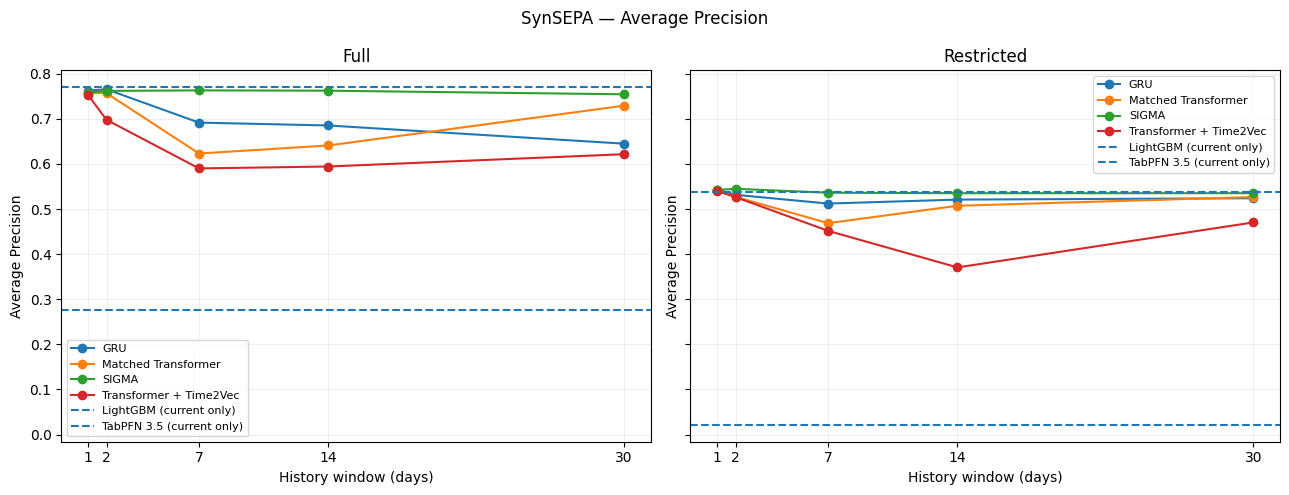

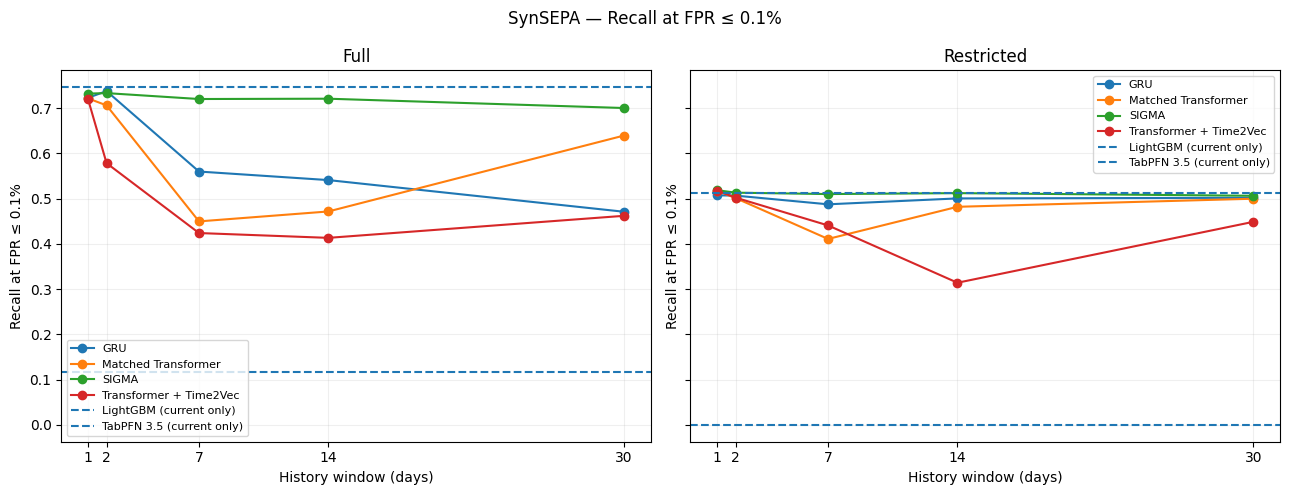

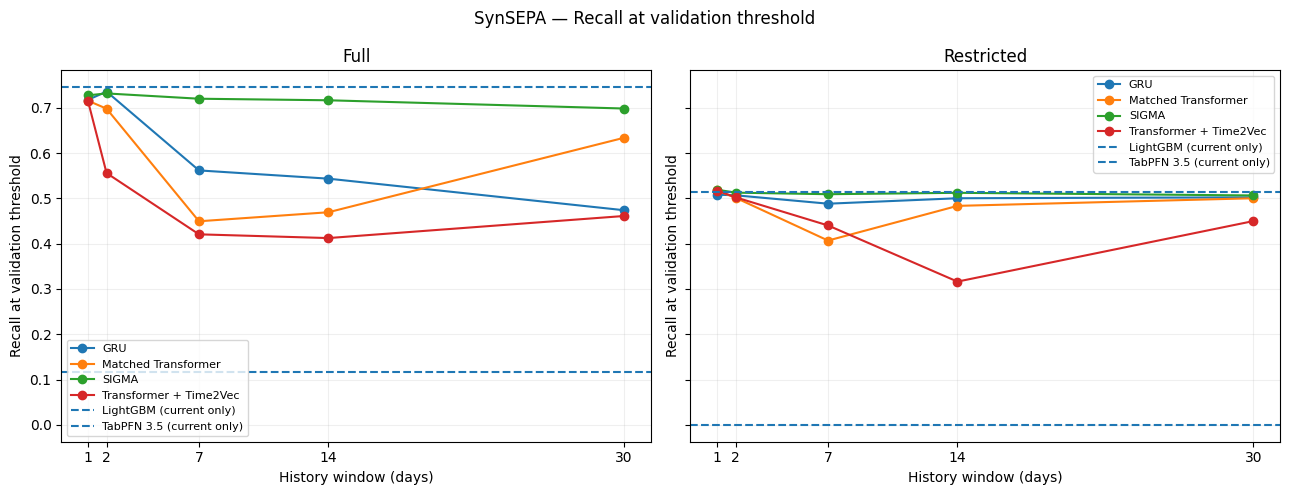

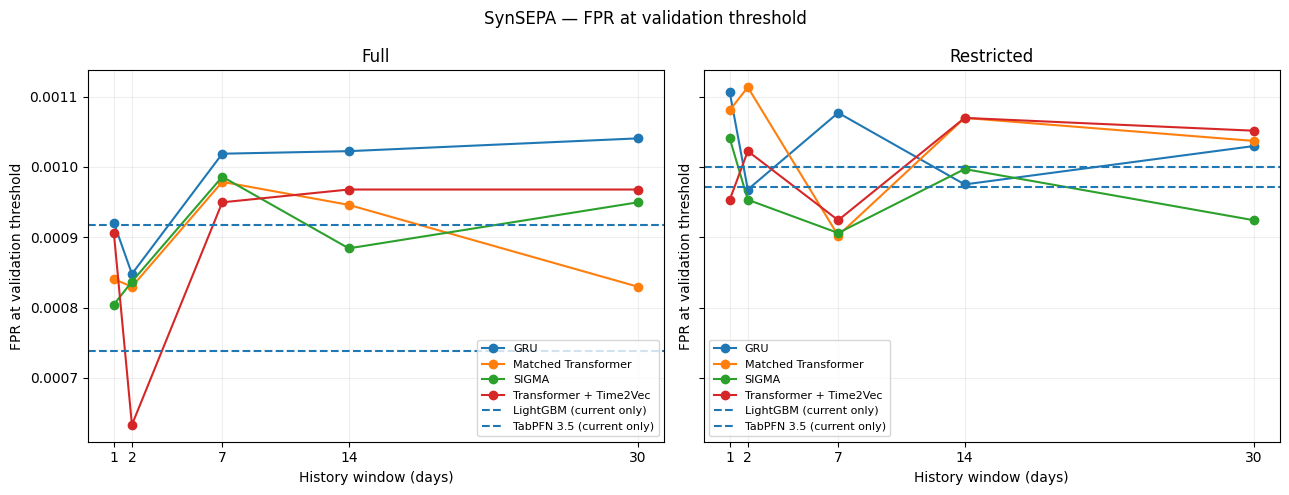

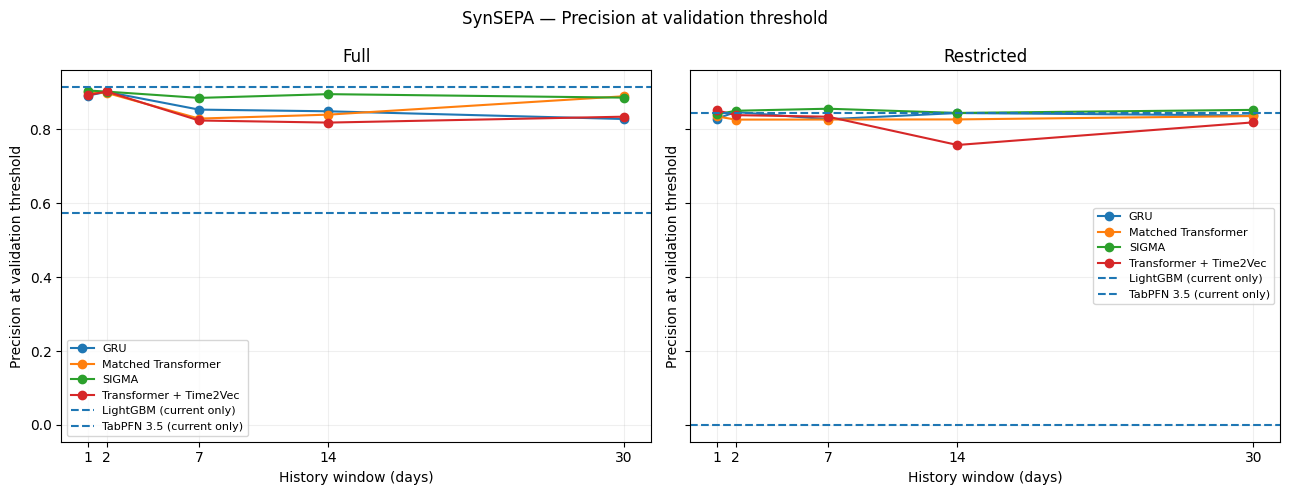

condition                          Full  Restricted  Full_minus_Restricted_pp
arm      days seed classifier                                                
current  0    0    LightGBM    0.276133    0.021458                 25.467563
                   TabPFN 3.5  0.770220    0.537212                 23.300825
gru      1    0    TabPFN 3.5  0.762844    0.543091                 21.975282
         2    0    TabPFN 3.5  0.765587    0.531579                 23.400838
         7    0    TabPFN 3.5  0.691734    0.512181                 17.955245
         14   0    TabPFN 3.5  0.685354    0.520971                 16.438374
         30   0    TabPFN 3.5  0.645050    0.523999                 12.105089
matched  1    0    TabPFN 3.5  0.758218    0.541179                 21.703958
         2    0    TabPFN 3.5  0.756829    0.527117                 22.971208
         7    0    TabPFN 3.5  0.623161    0.468708                 15.445270
         14   0    TabPFN 3.5  0.641013    0.507289                 13.372388
         30   0    TabPFN 3.5  0.729285    0.526680                 20.260493
sigma    1    0    TabPFN 3.5  0.758337    0.542400                 21.593699
         2    0    TabPFN 3.5  0.762003    0.544951                 21.705245
         7    0    TabPFN 3.5  0.763199    0.536262                 22.693645
         14   0    TabPFN 3.5  0.762524    0.535137                 22.738689
         30   0    TabPFN 3.5  0.754490    0.535138                 21.935211
time2vec 1    0    TabPFN 3.5  0.752767    0.540200                 21.256792
         2    0    TabPFN 3.5  0.697862    0.526393                 17.146818
         7    0    TabPFN 3.5  0.590123    0.451735                 13.838768
         14   0    TabPFN 3.5  0.594371    0.370579                 22.379197
         30   0    TabPFN 3.5  0.621651    0.470300                 15.135118

,condition,arm,days,seed,AP,baseline_AP,AP_gain_pp
0,Full,gru,1,0,0.762844,0.770220,-0.737626
1,Restricted,gru,1,0,0.543091,0.537212,0.587916
2,Full,gru,2,0,0.765587,0.770220,-0.463308
3,Restricted,gru,2,0,0.531579,0.537212,-0.563321
4,Full,gru,7,0,0.691734,0.770220,-7.848673
5,Restricted,gru,7,0,0.512181,0.537212,-2.503094
6,Full,gru,14,0,0.685354,0.770220,-8.486589
7,Restricted,gru,14,0,0.520971,0.537212,-1.624138
8,Full,gru,30,0,0.645050,0.770220,-12.517040
9,Restricted,gru,30,0,0.523999,0.537212,-1.321304


Completed: 44 / 44
Saved: /content/drive/MyDrive/26-2_AI_project/processed/synsepa/four_encoders_full_restricted_v1


In [49]:
result=progress()
assert len(result),'실험을 먼저 실행하세요'
cols=['condition','history_encoder','days','seed','classifier','AP','PR_AUC','Recall_at_FPR','fixed_recall','fixed_fpr','fixed_precision','TP','FP','FN','TN']
display(result[cols].sort_values(['condition','days','history_encoder','classifier']))
summary=result.groupby(['condition','history_encoder','classifier','days']).agg(AP=('AP','mean'),AP_std=('AP','std'),Recall_at_FPR=('Recall_at_FPR','mean'),fixed_recall=('fixed_recall','mean'),fixed_fpr=('fixed_fpr','mean'),fixed_precision=('fixed_precision','mean'),n=('seed','nunique')).reset_index()
write_csv(OUT/'summary.csv',summary)
for metric,ylabel in [('AP','Average Precision'),('Recall_at_FPR','Recall at FPR ≤ 0.1%'),('fixed_recall','Recall at validation threshold'),('fixed_fpr','FPR at validation threshold'),('fixed_precision','Precision at validation threshold')]:
    fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
    for condition,ax in zip(CONDITIONS,axes):
        q=summary[summary.condition==condition]
        for name in NAMES.values():
            a=q[(q.history_encoder==name)&(q.classifier=='TabPFN 3.5')].sort_values('days')
            if len(a): ax.plot(a.days,a[metric],marker='o',label=name)
        for clf in ['LightGBM','TabPFN 3.5']:
            a=q[(q.history_encoder=='Current only')&(q.classifier==clf)]
            if len(a): ax.axhline(a[metric].iloc[0],linestyle='--',label=f'{clf} (current only)')
        ax.set(xticks=RUN_DAYS,xlabel='History window (days)',ylabel=ylabel,title=condition); ax.grid(alpha=.2); ax.legend(fontsize=8)
    fig.suptitle(f'SynSEPA — {ylabel}'); fig.tight_layout()
    for ext in ['png','svg']: fig.savefig(OUT/'plots'/f'{metric}.{ext}',dpi=180,bbox_inches='tight')
    plt.show(); plt.close(fig)
wide=result.pivot(index=['arm','days','seed','classifier'],columns='condition',values='AP')
if set(CONDITIONS)<=set(wide.columns):
    wide['Full_minus_Restricted_pp']=(wide['Full']-wide['Restricted'])*100
    display(wide); write_csv(OUT/'delta_full_vs_restricted.csv',wide.reset_index())
# Compare sequence gains against current-only TabPFN, per condition and seed.
baseline=result[(result.arm=='current')&(result.classifier=='TabPFN 3.5')][['condition','seed','AP']].rename(columns={'AP':'baseline_AP'})
gains=result[result.arm!='current'].merge(baseline,on=['condition','seed'],how='left')
if len(gains):
    gains['AP_gain_pp']=(gains.AP-gains.baseline_AP)*100
    display(gains[['condition','arm','days','seed','AP','baseline_AP','AP_gain_pp']]); write_csv(OUT/'delta_vs_current.csv',gains)
print('Completed:',len(result),'/',len(PLAN)); print('Saved:',OUT)

### 해석과 제한
- Full의 높은 AP가 국가 생성 규칙의 shortcut일 가능성, Restricted에도 다른 편향이 남을 가능성을 함께 보고한다.
- `Recall_at_FPR`은 Test ROC에서 계산한 진단 지표이며 운영 threshold는 Val에서 결정한다. `fixed_*`, TP/FP/FN/TN은 Val threshold를 그대로 적용한 Test 결과이다.
- 모델은 각 데이터셋에서 새로 학습하며 원본 데이터셋의 가중치를 전이하지 않는다. 과거 이력만을 사용하는 Encoder는 Full/Restricted에서 공유한다.
- SIGMA는 공식 설정을 FDS에 적용한 순수 Torch scan 구현으로 native CUDA 속도 비교가 아니다. 기존 Time2Vec TF와 Matched TF의 폭이 다르므로 독립적인 Time2Vec 효과를 주장하지 않는다. Seed 0은 탐색적 실험이다. 모든 Test 결과를 본 후 모델/데이터를 선택했다면 이를 탐색적 분석으로 명시한다.
